## `meshlab` tutorial

Generate a boundary-layer mesh around an L-shaped object and collapse short front edges during layer growth.

### 1. Import packages
---

In [1]:
import numpy as np

from copy import deepcopy

from meshlab.data import Mesh, Contour
from meshlab.operations import insert_contour, compute_normals, advance_front, compute_angles, smooth_normals
from meshlab.operations import find_short_edges, collapse_edges
from meshlab.visualization import plot_mesh

from functions.create_polygon import create_polygon

### 2. Define parameters
---

In [2]:
num_layers = 10                # Number of layers
height = 0.04                 # First layer height
growth_rate = 1.10            # Ratio between two consecutive layers
points_per_edge = 5           # Number of points per polygon side
min_edge_ratio = 1.5          # Minimum edge length relative to current layer height

### 3. Geometry definition
---

In [3]:
# Define vértices
vertices = np.array([
        [  0, 0],
        [  0, 1],
        [-.5, 1],
        [-.5,-1],
        [  1,-1],
        [  1, 0],
])

# Create points
points = create_polygon(
    vertices,
    points_per_edge=[points_per_edge] * len(vertices),
)

### 4. Create boundary layer mesh and collapse short edges
---
After each advance, `find_short_edges(mesh, front, min_edge_ratio * h)` returns the short edges. Pass these original vertex-index pairs to `collapse_edges(mesh, front, edges)` to obtain the updated front and an index map.

Apply that map to the surface contour before continuing. The next iteration recomputes normals and angles on the updated front. Each example starts with a fresh mesh. Collapsed quadrilaterals may become triangles; inadmissible collapses are skipped.

#### 4.1. Example 1
Central normals, without height correction. Short edges near the reentrant corner are collapsed as the front grows.

Initialize mesh, surface and front

In [4]:
# Initialize mesh and surfaces
mesh = Mesh()
surface = Contour("surface")

# Insert contour into mesh
insert_contour(mesh, surface, points)

# Create front based on surfaces
front = deepcopy(surface)
front.name = "Front"

Advance the layers and collapse short front edges

Layer 4: collapsed 2 short edges.
Layer 7: collapsed 2 short edges.
Layer 8: collapsed 1 short edges.
Layer 10: collapsed 2 short edges.
Total collapsed edges: 7


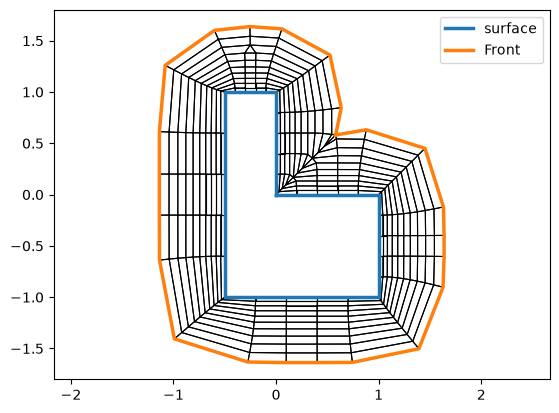

In [5]:
h = height
total_collapsed = 0
for layer in range(num_layers):
    # Compute the front normals
    normals = compute_normals(mesh, front)

    # Advance the front creating new vertices based on the normals
    front = advance_front(mesh, front, normals, h)

    # Detect and collapse short edges of the current front
    edges = find_short_edges(mesh, front, min_edge_ratio * h)
    previous_count = front.num_indices
    front, index_map = collapse_edges(mesh, front, edges)

    # Vertex compaction also changes indices stored in other contours
    surface.indices[:surface.num_indices] = index_map[
        surface.indices[:surface.num_indices]
    ]

    collapsed = previous_count - front.num_indices
    total_collapsed += collapsed
    if collapsed:
        print(f"Layer {layer + 1}: collapsed {collapsed} short edges.")

    # Update height
    h *= growth_rate

print(f"Total collapsed edges: {total_collapsed}")

# Visualize the mesh
plot_mesh(mesh, [surface, front])

#### 4.2. Example 2
Bisector normals with height correction, followed by short-edge detection and collapse at every layer.

Initialize mesh, surface and front

In [6]:
# Initialize mesh and surfaces
mesh = Mesh()
surface = Contour("surface")

# Insert contour into mesh
insert_contour(mesh, surface, points)

# Create front based on surfaces
front = deepcopy(surface)
front.name = "Front"

Advance the layers and collapse short front edges

Layer 3: collapsed 2 short edges.
Layer 6: collapsed 2 short edges.
Layer 7: collapsed 3 short edges.
Layer 9: collapsed 2 short edges.
Total collapsed edges: 9


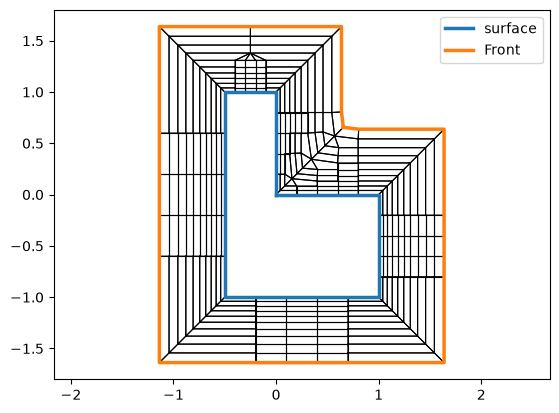

In [7]:
h = height
total_collapsed = 0
for layer in range(num_layers):
    # Compute the front normals
    normals = compute_normals(mesh, front, method="bisector")

    # Compute angles and correct height
    angles = compute_angles(mesh, front)
    array = h / np.sin(angles / 2)

    # Advance the front creating new vertices based on the normals
    front = advance_front(mesh, front, normals, array)

    # Detect and collapse short edges of the current front
    edges = find_short_edges(mesh, front, min_edge_ratio * h)
    previous_count = front.num_indices
    front, index_map = collapse_edges(mesh, front, edges)

    # Vertex compaction also changes indices stored in other contours
    surface.indices[:surface.num_indices] = index_map[
        surface.indices[:surface.num_indices]
    ]

    collapsed = previous_count - front.num_indices
    total_collapsed += collapsed
    if collapsed:
        print(f"Layer {layer + 1}: collapsed {collapsed} short edges.")

    # Update height
    h *= growth_rate

print(f"Total collapsed edges: {total_collapsed}")

# Visualize the mesh
plot_mesh(mesh, [surface, front])

#### 4.3. Example 3
Bisector normals, corrected heights and normal smoothing, followed by the same short-edge checks. Smoothing changes edge lengths, so this example may have fewer or no collapses for the chosen parameters.

Initialize mesh, surface and front

In [8]:
# Initialize mesh and surfaces
mesh = Mesh()
surface = Contour("surface")

# Insert contour into mesh
insert_contour(mesh, surface, points)

# Create front based on surfaces
front = deepcopy(surface)
front.name = "Front"

Advance the layers and collapse short front edges

Layer 7: collapsed 2 short edges.
Total collapsed edges: 2


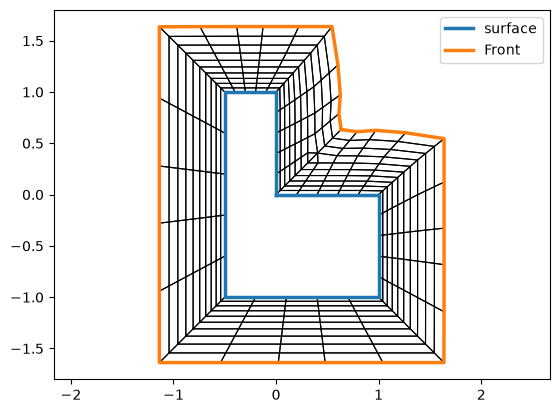

In [9]:
h = height
total_collapsed = 0
for layer in range(num_layers):
    # Compute the front normals
    normals = compute_normals(mesh, front, method="bisector")

    # Smooth normals
    rotation = np.zeros_like(normals[:, 0])
    for _ in range(5):
        normals, r = smooth_normals(normals, 1.0)
        rotation = rotation + r

    # Compute angles and correct height
    angles = compute_angles(mesh, front)
    array = h / np.sin(angles / 2 + np.abs(rotation))

    # Advance the front creating new vertices based on the normals
    front = advance_front(mesh, front, normals, array)

    # Detect and collapse short edges of the current front
    edges = find_short_edges(mesh, front, min_edge_ratio * h)
    previous_count = front.num_indices
    front, index_map = collapse_edges(mesh, front, edges)

    # Vertex compaction also changes indices stored in other contours
    surface.indices[:surface.num_indices] = index_map[
        surface.indices[:surface.num_indices]
    ]

    collapsed = previous_count - front.num_indices
    total_collapsed += collapsed
    if collapsed:
        print(f"Layer {layer + 1}: collapsed {collapsed} short edges.")

    # Update height
    h *= growth_rate

print(f"Total collapsed edges: {total_collapsed}")

# Visualize the mesh
plot_mesh(mesh, [surface, front])